# Compréhensibilité des fiches services, évaluée par un LLM

Ce carnet présente les résultats de l'exploration décrite dans [spec.md](spec.md) et [plan.md](plan.md) : un modèle de langage lit des fiches services du point de vue d'une personne bénéficiaire, sans connaissance du vocabulaire administratif ou du travail social, et note leur compréhensibilité de 1 à 5.

Il lit uniquement les fichiers produits par les scripts (`sample.parquet`, `scores.parquet`, `examples.parquet`) et ne fait aucun appel à l'API.

Pour le réexécuter :

```
uv run --with jupyter,nbconvert,ipykernel,duckdb,pandas,matplotlib,scipy,scikit-learn \
  jupyter nbconvert --to notebook --execute --inplace results.ipynb
```

In [ ]:
import textwrap

import duckdb
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy.stats import spearmanr
from sklearn.metrics import cohen_kappa_score, confusion_matrix

from analyse import AUDIENCES, LEVELS, distribution_query

# reference palette (dataviz skill), light mode
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRID = "#e1e0d9"
BASELINE = "#c3c2b7"
# ordinal ramp for score levels 1 -> 5 (blue 250, 350, 450, 550, 650)
LEVEL_COLORS = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]
LEVEL_INK = [INK, INK, "#ffffff", "#ffffff", "#ffffff"]
# full sequential ramp for the heatmap
SEQUENTIAL = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
# categorical slots 1-4
CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
CATEGORICAL_INK = ["#ffffff", "#ffffff", "#ffffff", INK]

mpl.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "figure.dpi": 110,
    "font.family": "sans-serif",
    "font.size": 9,
    "text.color": INK,
    "axes.labelcolor": INK_SECONDARY,
    "axes.titlecolor": INK,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.edgecolor": BASELINE,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
    "xtick.labelcolor": INK_SECONDARY,
    "ytick.labelcolor": INK_SECONDARY,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "legend.frameon": False,
})
pd.set_option("display.max_colwidth", 200)

con = duckdb.connect()
con.execute("""
    create table scores as
    select r.card_idx, r.run, r.score, r.audience, r.justification, r.model, r.error,
           s.id, s.source, s.n_services, s.score_qualite, s.description_length,
           s.nom, s.description
    from 'scores.parquet' r
    join 'sample.parquet' s using (card_idx)
""")
# main score: run 1
con.execute("create view main as select * from scores where run = 1 and score is not null")


def q(query: str) -> pd.DataFrame:
    return con.sql(query).df()

In [2]:
meta = q("""
    select any_value(model) as model, count(distinct card_idx) as cards, count(distinct run) as runs,
           count(*) as requests, count(*) - count(score) as failures
    from scores
""").iloc[0]
display(Markdown(f"""
**Juge** : `{meta.model}` (effort `medium`), via l'API Batches.
**Échantillon** : {meta.cards} fiches distinctes, {meta.runs} passages, {meta.requests} requêtes, {meta.failures} échec(s).

Échelle (du point de vue de la personne bénéficiaire, quel que soit le public visé) :

| Note | Sens |
|---|---|
| 1 | incompréhensible : jargon, sigles non expliqués, ou texte qui ne dit pas ce qu'est le service ou ne correspond pas à son nom |
| 2 | difficile à comprendre, le lecteur n'en retire qu'une idée vague |
| 3 | compréhensible avec effort, un peu de jargon ou une structure confuse |
| 4 | clair, difficultés mineures |
| 5 | immédiatement clair, langage simple |

Le juge indique aussi à qui la fiche semble s'adresser : `beneficiaire`, `professionnel`, `employeur` ou `indetermine`.
Seul ce qui est écrit est noté : une rubrique absente n'est pas pénalisée (la complétude relève du `score_qualite`).
"""))


**Juge** : `claude-haiku-5-5` (effort `medium`), via l'API Batches.
**Échantillon** : 253 fiches distinctes, 2 passages, 506 requêtes, 0 échec(s).

Échelle (du point de vue de la personne bénéficiaire, quel que soit le public visé) :

| Note | Sens |
|---|---|
| 1 | incompréhensible : jargon, sigles non expliqués, ou texte qui ne dit pas ce qu'est le service ou ne correspond pas à son nom |
| 2 | difficile à comprendre, le lecteur n'en retire qu'une idée vague |
| 3 | compréhensible avec effort, un peu de jargon ou une structure confuse |
| 4 | clair, difficultés mineures |
| 5 | immédiatement clair, langage simple |

Le juge indique aussi à qui la fiche semble s'adresser : `beneficiaire`, `professionnel`, `employeur` ou `indetermine`.
Seul ce qui est écrit est noté : une rubrique absente n'est pas pénalisée (la complétude relève du `score_qualite`).


## 1. Échantillon

L'unité est la **fiche distincte** : beaucoup de services partagent exactement le même texte. On tire au plus 20 fiches distinctes par source (toutes quand il y en a moins), avec une graine fixe. Chaque fiche garde `n_services`, le nombre de services de sa source qui partagent ce texte.

In [3]:
q("""
    with totals as (select source, count(*) as services_source from 'services.parquet' group by source)
    select source,
           count(*) as fiches_tirees,
           sum(n_services)::bigint as services_couverts,
           any_value(services_source) as services_source,
           round(100 * sum(n_services) / any_value(services_source), 1) as pct_couvert
    from 'sample.parquet' join totals using (source)
    group by source
    order by source
""")

,source,fiches_tirees,services_couverts,services_source,pct_couvert
0,action-logement,20,2320,2552,90.9
1,agefiph,20,400,760,52.6
2,carif-oref,20,25,6381,0.4
3,cd35,20,20,778,2.6
4,dora,20,23,22721,0.1
5,finess,2,2048,2048,100.0
6,france-travail,11,9735,9735,100.0
7,fredo,20,21,3368,0.6
8,ma-boussole-aidants,20,14199,14309,99.2
9,mediation-numerique,20,20,16597,0.1


finess et france-travail n'ont que 2 et 11 fiches distinctes : l'échantillon les couvre entièrement. ma-boussole-aidants et action-logement ont peu de fiches distinctes, chacune partagée par beaucoup de services.

## 2. Fiabilité du juge

Le juge a noté tout l'échantillon deux fois. Sans jeu de référence annoté par des humains, la cohérence entre les deux passages est le seul contrôle : elle mesure la stabilité de la note, pas sa justesse.

In [4]:
pairs = q("""
    select r1.card_idx, r1.score as score_1, r2.score as score_2,
           r1.audience as audience_1, r2.audience as audience_2
    from scores r1 join scores r2 using (card_idx)
    where r1.run = 1 and r2.run = 2 and r1.score is not null and r2.score is not null
""")
pd.DataFrame({
    "indicateur": [
        "fiches notées deux fois",
        "accord exact",
        "accord à 1 point près",
        "kappa pondéré quadratique",
        "accord sur le public visé",
    ],
    "valeur": [
        f"{len(pairs)}",
        f"{(pairs.score_1 == pairs.score_2).mean():.1%}",
        f"{((pairs.score_1 - pairs.score_2).abs() <= 1).mean():.1%}",
        f"{cohen_kappa_score(pairs.score_1, pairs.score_2, weights='quadratic', labels=LEVELS):.3f}",
        f"{(pairs.audience_1 == pairs.audience_2).mean():.1%}",
    ],
}).set_index("indicateur")

,valeur
indicateur,
fiches notées deux fois,253
accord exact,75.1%
accord à 1 point près,99.6%
kappa pondéré quadratique,0.833
accord sur le public visé,89.7%


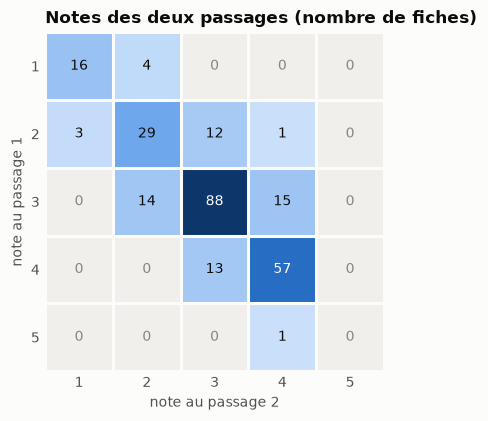

In [5]:
matrix = confusion_matrix(pairs.score_1, pairs.score_2, labels=LEVELS)
cmap = mpl.colors.LinearSegmentedColormap.from_list("blues", SEQUENTIAL)

fig, ax = plt.subplots(figsize=(4.6, 4.0))
cmap.set_bad("#f0efec")  # empty cells recede to neutral gray
ax.imshow(np.ma.masked_equal(matrix, 0), cmap=cmap, vmin=0, vmax=matrix.max())
# 2px surface gap between cells
ax.set_xticks(np.arange(-0.5, 5, 1), minor=True)
ax.set_yticks(np.arange(-0.5, 5, 1), minor=True)
ax.grid(which="minor", color=SURFACE, linewidth=2)
ax.tick_params(which="minor", length=0)
for i in range(5):
    for j in range(5):
        value = matrix[i, j]
        ink = "#ffffff" if value > matrix.max() * 0.45 else INK
        ax.text(j, i, str(value), ha="center", va="center", color=ink if value else INK_MUTED, fontsize=9)
ax.set_xticks(range(5), LEVELS)
ax.set_yticks(range(5), LEVELS)
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xlabel("note au passage 2")
ax.set_ylabel("note au passage 1")
ax.set_title("Notes des deux passages (nombre de fiches)")
plt.show()

Presque tous les désaccords portent sur un seul point, surtout entre 2, 3 et 4. La note est assez stable pour comparer les sources ; la suite utilise le **passage 1**.

## 3. Comparaison par source

`s1` à `s5` sont les parts de chaque note, `moyenne` et `mediane` portent sur les fiches. Avec 20 fiches au plus par source, ces chiffres sont **indicatifs** : un écart de quelques dixièmes de point entre deux sources n'est pas significatif.

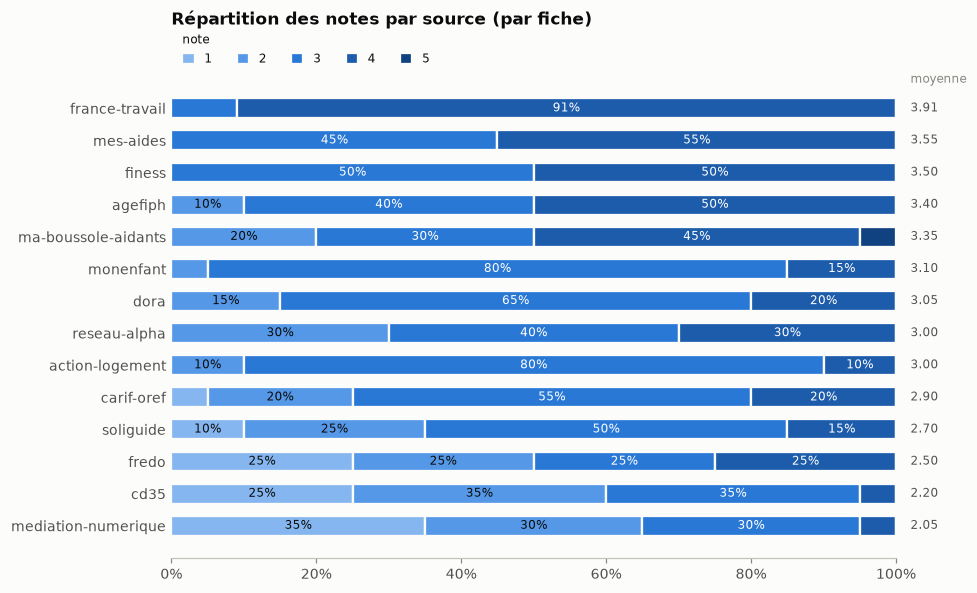

,fiches,s1,s2,s3,s4,s5,moyenne,mediane
source,,,,,,,,
france-travail,11,0.00,0.00,0.09,0.91,0.00,3.91,4
mes-aides,20,0.00,0.00,0.45,0.55,0.00,3.55,4
finess,2,0.00,0.00,0.50,0.50,0.00,3.50,3
agefiph,20,0.00,0.10,0.40,0.50,0.00,3.40,3
ma-boussole-aidants,20,0.00,0.20,0.30,0.45,0.05,3.35,3
monenfant,20,0.00,0.05,0.80,0.15,0.00,3.10,3
dora,20,0.00,0.15,0.65,0.20,0.00,3.05,3
action-logement,20,0.00,0.10,0.80,0.10,0.00,3.00,3
reseau-alpha,20,0.00,0.30,0.40,0.30,0.00,3.00,3


In [6]:
def by_source(where: str = "true", weight: str = "1") -> pd.DataFrame:
    df = q(distribution_query(where=where, weight=weight))
    return df.rename(columns={"cards": "fiches", "weight": "poids", "mean": "moyenne", "median": "mediane"})


def plot_levels(df: pd.DataFrame, title: str) -> None:
    """100% stacked horizontal bars of score levels, sources ordered by mean."""
    df = df.sort_values("moyenne").reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(8.5, 0.32 * len(df) + 1.2))
    left = np.zeros(len(df))
    for level, color, ink in zip(LEVELS, LEVEL_COLORS, LEVEL_INK):
        share = df[f"s{level}"].to_numpy()
        ax.barh(df.source, share, left=left, height=0.62, color=color,
                edgecolor=SURFACE, linewidth=1.5, label=f"{level}")
        for y, (x, s) in enumerate(zip(left, share)):
            if s >= 0.1:
                ax.text(x + s / 2, y, f"{s:.0%}", ha="center", va="center", color=ink, fontsize=8)
        left += share
    for y, m in enumerate(df.moyenne):
        ax.text(1.02, y, f"{m:.2f}", va="center", color=INK_SECONDARY, fontsize=8)
    ax.text(1.02, len(df) - 0.3, "moyenne", va="bottom", color=INK_MUTED, fontsize=8)
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(xmax=1))
    ax.tick_params(axis="y", length=0)
    ax.spines["left"].set_visible(False)
    ax.legend(title="note", ncols=5, loc="lower left", bbox_to_anchor=(0, 1.0),
              handlelength=1, handleheight=1, alignment="left", title_fontsize=8, fontsize=8)
    ax.set_title(title, pad=34)
    plt.show()


per_card = by_source()
plot_levels(per_card, "Répartition des notes par source (par fiche)")
per_card.drop(columns="poids").set_index("source")

### Pondéré par le nombre de services

Une fiche partagée par 885 services pèse 885 fois plus qu'une fiche unique. La pondération montre ce que voit un utilisateur qui parcourt les services plutôt que les textes distincts.

In [7]:
weighted = by_source(weight="n_services")
weighted.set_index("source")

,fiches,poids,s1,s2,s3,s4,s5,moyenne,mediane
source,,,,,,,,,
finess,2,2048,0.00,0.00,0.05,0.95,0.0,3.95,4
france-travail,11,9735,0.00,0.00,0.09,0.91,0.0,3.91,4
mes-aides,20,20,0.00,0.00,0.45,0.55,0.0,3.55,4
agefiph,20,400,0.00,0.10,0.40,0.50,0.0,3.40,3
monenfant,20,20,0.00,0.05,0.80,0.15,0.0,3.10,3
dora,20,23,0.00,0.13,0.70,0.17,0.0,3.04,3
action-logement,20,2320,0.00,0.10,0.80,0.10,0.0,3.00,3
ma-boussole-aidants,20,14199,0.00,0.00,0.99,0.00,0.0,3.00,3
reseau-alpha,20,20,0.00,0.30,0.40,0.30,0.0,3.00,3


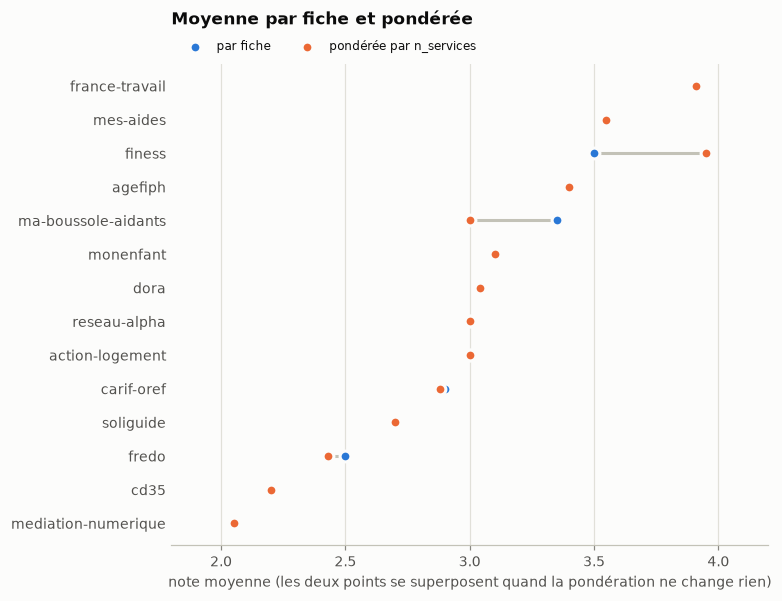

In [8]:
compare = per_card[["source", "moyenne"]].merge(
    weighted[["source", "moyenne"]], on="source", suffixes=("_fiche", "_pondere")
).sort_values("moyenne_fiche").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(7, 0.32 * len(compare) + 1.2))
y = np.arange(len(compare))
ax.hlines(y, compare.moyenne_fiche, compare.moyenne_pondere, color=BASELINE, linewidth=2)
ax.scatter(compare.moyenne_fiche, y, s=50, color=CATEGORICAL[0], edgecolor=SURFACE, linewidth=2, zorder=3, label="par fiche")
ax.scatter(compare.moyenne_pondere, y, s=50, color=CATEGORICAL[1], edgecolor=SURFACE, linewidth=2, zorder=3, label="pondérée par n_services")
ax.set_yticks(y, compare.source)
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
ax.set_xlim(1.8, 4.2)
ax.grid(axis="x")
ax.set_axisbelow(True)
ax.set_xlabel("note moyenne (les deux points se superposent quand la pondération ne change rien)")
ax.legend(ncols=2, loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=8)
ax.set_title("Moyenne par fiche et pondérée", pad=26)
plt.show()

In [9]:
ft = q("""
    select count(*) as n, min(n_services) as min_n, max(n_services) as max_n
    from main where source = 'france-travail'
""").iloc[0]
cmp = compare.set_index("source")
fi, mba = cmp.loc["finess"], cmp.loc["ma-boussole-aidants"]
display(Markdown(
    f"La pondération change surtout finess ({fi.moyenne_fiche:.2f} → {fi.moyenne_pondere:.2f}) et "
    f"ma-boussole-aidants ({mba.moyenne_fiche:.2f} → {mba.moyenne_pondere:.2f}). "
    f"Elle ne change rien pour france-travail : ses {ft.n} fiches sont partagées chacune par "
    f"{ft.min_n if ft.min_n == ft.max_n else f'{ft.min_n} à {ft.max_n}'} services."
))

La pondération change surtout finess (3.50 → 3.95) et ma-boussole-aidants (3.35 → 3.00). Elle ne change rien pour france-travail : ses 11 fiches sont partagées chacune par 885 services.

### Fiches rédigées pour les bénéficiaires

Certaines fiches s'adressent à des professionnels ou à des employeurs ; leur note reste donnée du point de vue de la personne bénéficiaire. En se limitant aux fiches que le juge considère écrites pour les bénéficiaires :

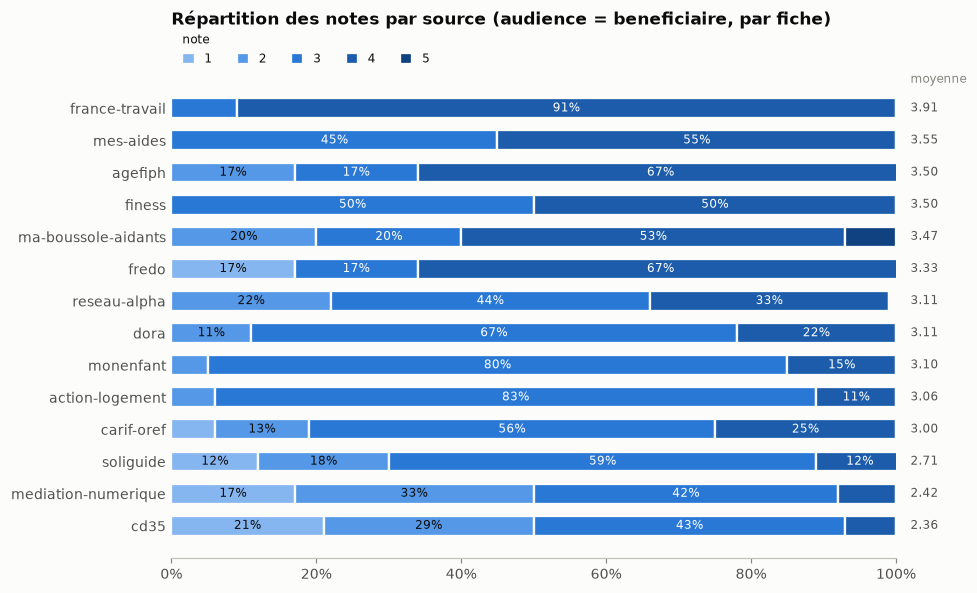

,fiches,s1,s2,s3,s4,s5,moyenne,mediane
source,,,,,,,,
france-travail,11,0.00,0.00,0.09,0.91,0.00,3.91,4
mes-aides,20,0.00,0.00,0.45,0.55,0.00,3.55,4
agefiph,6,0.00,0.17,0.17,0.67,0.00,3.50,4
finess,2,0.00,0.00,0.50,0.50,0.00,3.50,3
ma-boussole-aidants,15,0.00,0.20,0.20,0.53,0.07,3.47,4
fredo,6,0.17,0.00,0.17,0.67,0.00,3.33,4
dora,18,0.00,0.11,0.67,0.22,0.00,3.11,3
reseau-alpha,18,0.00,0.22,0.44,0.33,0.00,3.11,3
monenfant,20,0.00,0.05,0.80,0.15,0.00,3.10,3


In [10]:
beneficiaire = by_source(where="audience = 'beneficiaire'")
plot_levels(beneficiaire, "Répartition des notes par source (audience = beneficiaire, par fiche)")
beneficiaire.drop(columns="poids").set_index("source")

In [11]:
by_source(where="audience = 'beneficiaire'", weight="n_services").set_index("source")

,fiches,poids,s1,s2,s3,s4,s5,moyenne,mediane
source,,,,,,,,,
finess,2,2048,0.00,0.00,0.05,0.95,0.00,3.95,4
france-travail,11,9735,0.00,0.00,0.09,0.91,0.00,3.91,4
ma-boussole-aidants,15,57,0.00,0.11,0.05,0.81,0.04,3.77,4
mes-aides,20,20,0.00,0.00,0.45,0.55,0.00,3.55,4
agefiph,6,120,0.00,0.17,0.17,0.67,0.00,3.50,4
fredo,6,6,0.17,0.00,0.17,0.67,0.00,3.33,4
reseau-alpha,18,18,0.00,0.22,0.44,0.33,0.00,3.11,3
dora,18,21,0.00,0.10,0.71,0.19,0.00,3.10,3
monenfant,20,20,0.00,0.05,0.80,0.15,0.00,3.10,3


## 4. Public visé

Part des fiches de chaque source selon le public auquel elles semblent s'adresser.

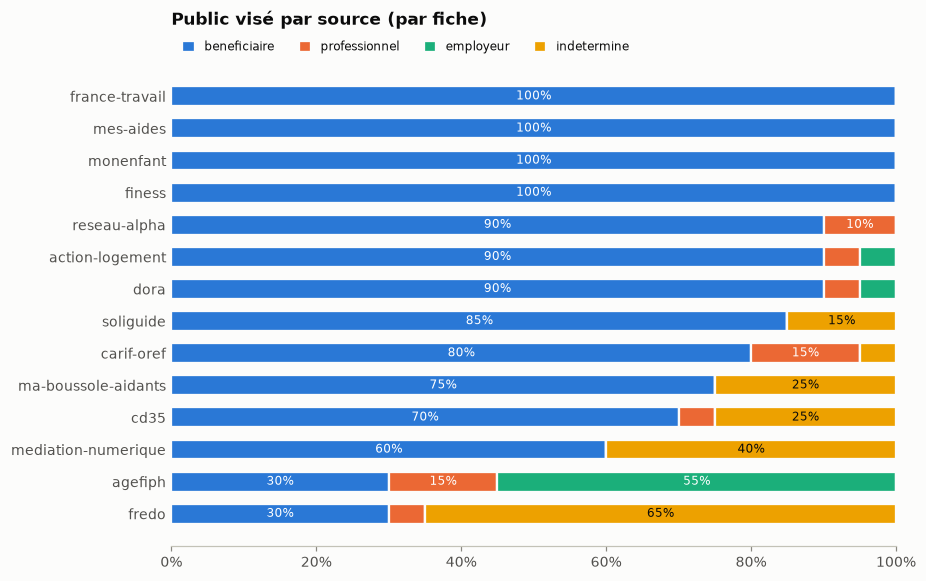

,fiches,beneficiaire,professionnel,employeur,indetermine
source,,,,,
fredo,20,0.30,0.05,0.00,0.65
agefiph,20,0.30,0.15,0.55,0.00
mediation-numerique,20,0.60,0.00,0.00,0.40
cd35,20,0.70,0.05,0.00,0.25
ma-boussole-aidants,20,0.75,0.00,0.00,0.25
carif-oref,20,0.80,0.15,0.00,0.05
soliguide,20,0.85,0.00,0.00,0.15
dora,20,0.90,0.05,0.05,0.00
action-logement,20,0.90,0.05,0.05,0.00


In [12]:
aud = q(f"""
    select source, count(*) as fiches,
           {", ".join(f"avg((audience = '{a}')::int) as {a}" for a in AUDIENCES)}
    from main group by source
""").sort_values("beneficiaire").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8.5, 0.32 * len(aud) + 1.2))
left = np.zeros(len(aud))
for a, color, ink in zip(AUDIENCES, CATEGORICAL, CATEGORICAL_INK):
    share = aud[a].to_numpy()
    ax.barh(aud.source, share, left=left, height=0.62, color=color, edgecolor=SURFACE, linewidth=1.5, label=a)
    for y, (x, s) in enumerate(zip(left, share)):
        if s >= 0.1:
            ax.text(x + s / 2, y, f"{s:.0%}", ha="center", va="center", color=ink, fontsize=8)
    left += share
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(xmax=1))
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
ax.legend(ncols=4, loc="lower left", bbox_to_anchor=(0, 1.0), handlelength=1, handleheight=1, fontsize=8)
ax.set_title("Public visé par source (par fiche)", pad=26)
plt.show()
aud.set_index("source").round(2)

agefiph s'adresse surtout aux employeurs. Les fiches `indetermine` de fredo, mediation-numerique et cd35 sont souvent des textes très courts ou génériques.

## 5. Corrélations

Corrélation de Spearman entre la note (passage 1) et deux grandeurs connues pour chaque fiche : le `score_qualite` de son service représentatif (qui mesure surtout la complétude) et la longueur de la description.

In [13]:
main = q("select score, score_qualite, description_length from main")
rows = []
for col in ["score_qualite", "description_length"]:
    sub = main.dropna(subset=[col])
    rho, p_value = spearmanr(sub.score, sub[col])
    rows.append({"variable": col, "rho": round(rho, 3), "p": f"{p_value:.3g}", "n": len(sub)})
pd.DataFrame(rows).set_index("variable")

,rho,p,n
variable,,,
score_qualite,0.194,0.00198,253
description_length,-0.063,0.318,253


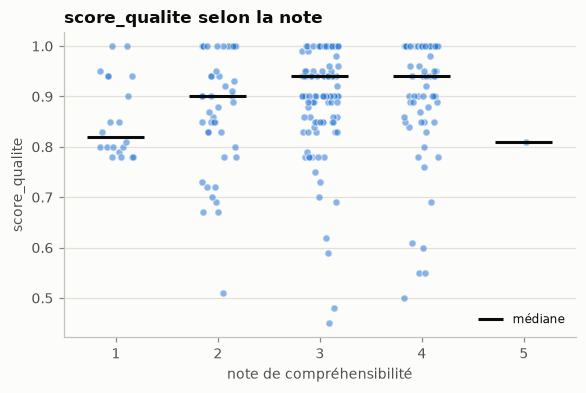

In [14]:
rng = np.random.default_rng(seed=0)
fig, ax = plt.subplots(figsize=(6, 3.6))
jitter = rng.uniform(-0.18, 0.18, size=len(main))
ax.scatter(main.score + jitter, main.score_qualite, s=22, color=CATEGORICAL[0], alpha=0.55, edgecolor=SURFACE, linewidth=0.8)
medians = main.groupby("score").score_qualite.median()
ax.hlines(medians.values, medians.index - 0.28, medians.index + 0.28, color=INK, linewidth=2, label="médiane")
ax.set_xticks(LEVELS)
ax.set_xlabel("note de compréhensibilité")
ax.set_ylabel("score_qualite")
ax.grid(axis="y")
ax.set_axisbelow(True)
ax.legend(loc="lower right", fontsize=8)
ax.set_title("score_qualite selon la note")
plt.show()

La note de compréhensibilité est faiblement liée au `score_qualite` et pas à la longueur : les deux mesurent des choses différentes, la compréhensibilité apporte une information que le `score_qualite` ne donne pas.

## 6. Exemples

Pour chaque note, jusqu'à 5 fiches de sources différentes, avec la justification du juge (`examples.parquet`). Descriptions tronquées.

In [15]:
def clean(text: str, width: int) -> str:
    text = " ".join(text.replace("\\n", " ").split())
    text = text.replace("#", "").replace("*", "").replace("|", "/")
    return textwrap.shorten(text, width=width, placeholder=" …")


examples = q("select * from 'examples.parquet' order by score, source")
for score, group in examples.groupby("score"):
    lines = [f"### Note {score}"]
    for row in group.itertuples():
        lines.append(
            f"**{clean(row.nom, 120)}** · {row.source} · public : {row.audience}\n\n"
            f"> {clean(row.description, 400)}\n\n"
            f"*Juge* : {row.justification}\n"
        )
    display(Markdown("\n".join(lines)))

### Note 1
**Master 2ème année mention français langue étrangère parcours politiques linguistiques éducatives** · carif-oref · public : beneficiaire

> Objectif de la formation Compétences attestées : Connaître et maîtriser les outils nécessaires à la conception de dispositifs didactiques et pédagogiques de formation en langues Appliquer les méthodes pédagogiques adaptées pour préparer des cours et les dispenser Maîtriser les règles de correction dans le cadre de productions écrites et orales Evaluer les compétences et les performances des …

*Juge* : Fiche entièrement en jargon universitaire (FLE, didactique, UE, M1, veille technologique, savoirs hautement spécialisés) sans expliquer ce qu'est le service ; le nom de la formation et la liste de compétences ne permettent pas au lecteur de comprendre ce qui est proposé ni pour qui.

**Accompagnement éducatif** · cd35 · public : professionnel

> Les Maisons d'Enfants à Caractère Social (MECS) accueillent les enfants dont les familles se trouvent en difficulté momentanée ou qui ne peuvent assumer de manière continue l'éducation de l'enfant. Les enfants qui y séjournent sont confiés par la famille, par le service d'aide sociale à l'enfance ou directement par le juge des enfants, sous réserve que l'établissement ait été spécialement …

*Juge* : Le nom « Accompagnement éducatif » ne correspond pas au texte, qui décrit une MECS, un établissement d'hébergement pour enfants, sans jamais expliquer ce qu'est une MECS. Le sigle n'est pas développé, et « habilité au titre de l'assistance éducative », « aide sociale à l'enfance » et « juge des enfants » sont du jargon administratif que le lecteur ne peut pas décoder seul.

**Ecoute / soutien** · fredo · public : indetermine

> L'institut médico-éducatif du Baobab est une structure qui met en oeuvre un accompagnement adapté et personnalisé en partenariat avec la famille dans les domaines éducatifs, psychologiques, pédagogique, professionnel et sociaux en vue de son intégration social et socialeL’accueil temporaire permet d’offrir aux personnes accueillies, une possibilité de prise en charge éducative temporaire …

*Juge* : Le nom « Ecoute / soutien » ne correspond pas au contenu, qui décrit un institut médico-éducatif. Le texte est très jargonneux : « IME », « UEEA », « Unité d'Enseignement Élémentaire Autisme » et « accueil temporaire » ne sont pas expliqués, et la phrase « intégration social et socialeL'accueil » est mal formée et confuse.

**Service d'accompagnement au numérique** · mediation-numerique · public : indetermine

> SANS RDV ET RDV

*Juge* : La description se limite à « SANS RDV ET RDV », qui ne dit pas en quoi consiste l'accompagnement numérique ni ce qu'on y fait. Seul le nom du service donne une idée, et encore très vague, du contenu proposé.

**Soutien scolaire** · soliguide · public : beneficiaire

> Archipélia propose des dispositifs permettant de renforcer les liens entre les familles et l'école : mieux comprendre le fonctionnement de l'école, participer à des projets partagés, mieux dialoguer avec l'institution scolaire, rencontrer d'autres parents ou encore préparer le passage de votre enfant dans un nouvel établissement. Accueil en français et anglais. Archipelia est un lieu de …

*Juge* : Le nom du service est « Soutien scolaire », mais la description parle de renforcer les liens entre familles et école, de participer à des projets partagés et de rencontrer d'autres parents, sans jamais mentionner d'aide aux devoirs ou de soutien aux élèves. Le lecteur ne peut pas savoir ce qui est réellement proposé, et des termes comme « dispositifs » et « institution scolaire » restent vagues.


### Note 2
**Evaluation finale - Socle de connaissances et de compétences professionnelles numérique (CléA Numérique)** · carif-oref · public : beneficiaire

> Objectif de la formation Validation des compétences Contenu de la formation 1 Evaluation finale

*Juge* : Le nom accumule le jargon « Socle de connaissances et de compétences professionnelles » et le sigle « CléA Numérique » sans explication. Le contenu se limite à « 1 Evaluation finale » et « Validation des compétences », ce qui ne permet de saisir qu'une idée vague d'une évaluation de compétences numériques.

**Consultation gratuite de notaire** · cd35 · public : indetermine

> La chambre interdépartementale des notaires de la cour d’appel de Rennes regroupe les notaires des Côtes-d’Armor, du Finistère, de l’Ille-et-Vilaine, de la Loire-Atlantique et du Morbihan. Les anciennes chambres des Notaires sont devenues des pôles territoriaux, qui peuvent continuer à recevoir du public. La compétence territoriale de la chambre interdépartementale correspond aux limites des 33 …

*Juge* : La fiche consacre presque tout son texte à décrire la chambre interdépartementale des notaires (« chambre interdépartementale », « cour d'appel », « pôles territoriaux », « déontologie », « marchés immobiliers », « accès au droit ») et ne mentionne la consultation gratuite qu'en une seule phrase finale, sans dire à qui elle s'adresse ni comment en bénéficier. Le lecteur comprend donc seulement vaguement qu'il existe des consultations juridiques gratuites à Ille-et-Vilaine.

**Information / orientation** · fredo · public : indetermine

> La procédure d'indemnisation des victimes permet de faire reconnaître la personne en tant que victime, de l'indemniser sans avoir nécessairement besoin d'attendre que l'auteur paie le montant des dommages et intérêts

*Juge* : Le texte reste vague : « procédure d'indemnisation », « dommages et intérêts » et « l'auteur » ne sont pas expliqués, et le lecteur ne sait pas à qui s'adresser ni quelles démarches suivre. Il ne correspond pas non plus clairement au nom « Information / orientation », alors qu'il décrit une procédure d'indemnisation.

**Service d'accompagnement au numérique** · mediation-numerique · public : indetermine

> Uniquement sur Rendez-vous

*Juge* : Le nom « Service d'accompagnement au numérique » donne une idée générale d'aide pour les outils numériques, mais la description se limite à « Uniquement sur Rendez-vous », une contrainte d'accès qui ne dit rien de ce qui est proposé. Le lecteur n'en retire qu'une idée vague.

**Point d’information et d’orientation** · soliguide · public : indetermine

> Connexion à internet, informations administratives La mission de l'association est de créer du lien social entre les habitants du quartier avec des équipements à destination des quartiers défavorisés : épicerie solidaire et boutique solidaire.

*Juge* : Le lecteur comprend vaguement qu'il y a un accès à internet, des informations administratives et une épicerie solidaire, mais le nom « Point d'information et d'orientation » ne correspond pas clairement à la description. Les termes « reste à vivre », « ménage », « commission » et « travailleur social » ne sont pas expliqués, et les modalités d'accès sont trop floues (« plage horaires déterminé avec la structure »).


### Note 3
**Conseil et accompagnement emploi handicap des entreprises** · agefiph · public : employeur

> En fonction des besoins de l'entreprise, l'expert Agefiph : informe l'entreprise sur ses obligations en matière d'emploi de personnes handicapées, les interlocuteurs utiles, les outils et solutions, analyse les besoins et conçoit avec l'entreprise un plan d'action sur-mesure. A cette étape, l'expert Agefiph peut mobiliser un prestataire pour réaliser un "diagnostic action", accompagne …

*Juge* : La fiche explique assez bien l'aide proposée aux entreprises (informer, concevoir un plan d'action, accompagner), mais elle reste difficile pour un lecteur non initié : le sigle « Agefiph » n'est jamais expliqué, « diagnostic action » et « plan d'action sur-mesure » sont du jargon, et « emploi de personnes handicapées » et « interlocuteurs utiles » restent vagues.

**Accueil collectif ponctuel : halte garderie - multi accueil** · cd35 · public : indetermine

> Les établissements ou services « multi -accueil » associent différentes formules d’accueil : accueil à temps partiel, accueil ponctuel ou en urgence, ou crèche / halte-garderie et crèche familiales L’objectif des multi-accueil est d’apporter la plus grande souplesse possible des solutions d’accueil qui sont proposées aux parents. En permettant de combiner accueil collectif et accueil familial, …

*Juge* : Le lecteur comprend qu'il s'agit d'un accueil de jeunes enfants (2 mois à 3 ans) avec des horaires souples, mais le texte est abstrait (« établissements ou services », « accueil familial », « horaires atypiques », « crèches parentales ») et le fonctionnement reste flou, par exemple qui salarie l'équipe et ce que signifie « accueil ponctuel ».

**Parcours d'insertion socioprofessionnel - Demandeur(se) d'emploi en situation de handicap** · dora · public : beneficiaire

> Cap emploi informe, conseille et accompagne les personnes en situation de handicap en recherche d’emploi et les employeurs privés et publics. Cap emploi est expert de la relation emploi/handicap. Cap emploi exerce une mission de service public. Il a pour rôle d'informer, conseiller et d'accompagner : les personnes qui ont un handicap reconnu ou en cours de reconnaissance dans : - l’élaboration …

*Juge* : La description générale (aider les personnes en situation de handicap à trouver un emploi) est compréhensible, mais le texte contient beaucoup de jargon non expliqué : « adéquation emploi/handicap », « lieu unique d'accompagnement (LUA) », « bénéficiaire de l'obligation d'emploi », « code des pensions militaires d'invalidité », « AAH », « CDAPH » et « carte mobilité inclusion ». La liste des conditions d'accès, sans explication, rend difficile de savoir si l'on est concerné.

**Diagnostic et adaptation du logement** · ma-boussole-aidants · public : beneficiaire

> Acteur proposant une analyse et des recommandations d’adaptation du logement, permettant d’en optimiser le confort et la sécurité. La prestation pouvant aller jusqu’au suivi voire la réalisation des travaux d’aménagement.

*Juge* : Le texte dit clairement qu'il s'agit d'analyser et d'adapter un logement pour le rendre plus confortable et sûr, mais des termes comme « optimiser » et « prestation » sont un peu administratifs, et « Acteur » reste vague sur la nature de l'organisme.

**Pass'Permis / Labouheyre** · mes-aides · public : beneficiaire

> La Ville de Labouheyre propose un dispositif d’aide au permis de conduire pour les personnes désirant obtenir le permis B (formation classique ou conduite accompagnée) ou le permis Moto (A, A1 ou A2). Montant 500 €

*Juge* : La fiche indique clairement l'aide (500 €) et son objet, mais elle contient du jargon et des sigles non expliqués (CAF, MSA, CCAS, quotient familial, responsabilité civile, Junior Association, service volontaire européen) et une structure confuse, avec des conditions et justificatifs mêlés et des guillemets parasites.


### Note 4
**Réaliser son Cv en anglais/ en allemand/ en espagnol** · france-travail · public : beneficiaire

> Vous vous demandez comment rédiger un bon CV en anglais/ en allemand ou en espagnol ? Quels sont les incontournables à respecter selon les pays visés ? Cet atelier-conseil vous permet de : - Identifier vos compétences à mettre en valeur dans un contexte interculturel - Rédiger votre CV en anglais/ en allemand/ en espagnol - Adapter votre CV aux attentes des recruteurs des pays ciblés - …

*Juge* : La fiche est claire : on comprend qu'il s'agit d'un atelier d'une demi-journée pour rédiger un CV en langue étrangère, avec des étapes simples et une façon de s'inscrire. Quelques difficultés mineures : le terme « incontournables », « contexte interculturel » et « recruteurs » sont un peu soutenus, et le sigle « CV » n'est pas expliqué, tout comme l'expression « espace personnel » reste vague sans précision.

**Crèches, assistantes maternelles** · ma-boussole-aidants · public : beneficiaire

> Solutions d’accueil pour les enfants qui ne vont pas encore à l’école. Certaines sont spécialement équipées et leur équipe est formée pour mieux accueillir les enfants avec un handicap.

*Juge* : La description est simple et compréhensible : des solutions d'accueil pour les enfants qui ne vont pas encore à l'école, avec des structures adaptées au handicap. Difficultés mineures : le terme « assistantes maternelles » n'est pas expliqué, et la tranche d'âge « 0 à 120 ans » est incohérente pour un service de garde d'enfants.

**Bourse au permis de conduire / La Turbie** · mes-aides · public : beneficiaire

> La mairie de la Turbie propose à ses jeunes habitants une bourse au permis de conduire d'un montant de 700€. Montant 700 €

*Juge* : La fiche dit clairement qu'il s'agit d'une aide de 700 € de la mairie pour le permis, réservée aux 17-25 ans résidant à La Turbie, et indique comment faire la demande. Les difficultés mineures tiennent à « Dernier avis d'imposition », à « Justificatif de revenus » sans précision, et à la formulation télégraphique de la rubrique publics (« resider dans la commune »).

**Atelier D'apprentissage du Français de Montrouge** · reseau-alpha · public : beneficiaire

> L’accès à un savoir de base et une ouverture à la culture sont indispensables pour bien vivre en société. C’est une des priorités du Secours Catholique-Caritas France. Le Secours Catholique propose des cours de Français langue étrangère (FLE) pour les personnes nouvellement arrivées qui ne maîtrisent pas la langue mais qui ont été scolarisées dans leur pays d’origine. Il anime également des …

*Juge* : Le texte explique clairement qu'il s'agit de cours de français pour personnes nouvellement arrivées ou jamais scolarisées, gratuits et sans condition de scolarité. Les niveaux A1, A1.1, A2, B1 et B2 ne sont pas expliqués, et « Étendue de la formation » ainsi que « lien social » restent peu clairs pour un lecteur non initié.

**Hébergement d’urgence** · soliguide · public : beneficiaire

> Le 115 assure l'écoute et l'orientation des personnes sans abri. Contacter le 115 est nécessaire pour être orienté vers un hébergement d'urgence sur le département de la Lozère. Cette orientation se fait en fonction des places disponibles. Le 115 fonctionne 7j/7 et 24h/24. Il a pour missions l'accueil, l'écoute et l'information, ainsi que l'évaluation et l'orientation. Avec sa vocation …

*Juge* : Le texte explique clairement qu'il faut appeler le 115 pour être orienté vers un hébergement d'urgence en Lozère, selon les places disponibles. Quelques termes administratifs gênent un peu la lecture, comme « garant », « vocation départementale » et « évaluation et orientation ».


### Note 5
**Soins à domicile** · ma-boussole-aidants · public : beneficiaire

> Intervention de professionnels de santé - médecins, infirmiers, kinésithérapeutes…- à domicile pour dispenser les soins nécessaires.

*Juge* : Le texte est court et en langage simple : il dit que des professionnels de santé (médecins, infirmiers, kinésithérapeutes) viennent soigner la personne chez elle. Le mot « kinésithérapeutes » est un terme professionnel, mais il reste compréhensible et le sens général est immédiat.


## 7. Limites

In [16]:
n_five = int(q("select count(*) as n from main where score = 5").n[0])
n_main = int(q("select count(*) as n from main").n[0])
missing = q("""
    select count(*) filter (
        where justification ilike '%comment en bénéficier%'
           or justification ilike '%à qui s''adresser%'
           or justification ilike '%ne dit pas%comment%'
           or justification ilike '%démarche%'
    ) as n, count(*) as total
    from scores where justification is not null
""").iloc[0]
display(Markdown(f"""
- **Petits effectifs** : au plus 20 fiches par source (2 pour finess, 11 pour france-travail). Les écarts entre sources proches ne sont pas significatifs.
- **Fiabilité n'est pas validité** : la note est stable d'un passage à l'autre, mais aucune fiche n'a été notée par des humains. On ne sait pas encore si le juge est trop sévère ou trop indulgent.
- **Notes resserrées** : {n_five} fiche sur {n_main} a reçu la note 5, presque tout se joue entre 2 et 4. Le libellé de la note 5 est peut-être trop exigeant.
- **Information manquante** : la consigne demande de ne pas pénaliser l'absence d'information, mais environ {missing.n / missing.total:.0%} des justifications ({missing.n} sur {missing.total}, repérage par mots-clés) évoquent encore ce qui manque (à qui s'adresser, démarches).
- **Écart avec la spec** : le libellé de la note 5 a été ajusté (« ce qu'il doit faire, *si la fiche l'indique* ») pour rester cohérent avec la règle « noter seulement ce qui est écrit ».
"""))


- **Petits effectifs** : au plus 20 fiches par source (2 pour finess, 11 pour france-travail). Les écarts entre sources proches ne sont pas significatifs.
- **Fiabilité n'est pas validité** : la note est stable d'un passage à l'autre, mais aucune fiche n'a été notée par des humains. On ne sait pas encore si le juge est trop sévère ou trop indulgent.
- **Notes resserrées** : 1 fiche sur 253 a reçu la note 5, presque tout se joue entre 2 et 4. Le libellé de la note 5 est peut-être trop exigeant.
- **Information manquante** : la consigne demande de ne pas pénaliser l'absence d'information, mais environ 13% des justifications (67 sur 506, repérage par mots-clés) évoquent encore ce qui manque (à qui s'adresser, démarches).
- **Écart avec la spec** : le libellé de la note 5 a été ajusté (« ce qu'il doit faire, *si la fiche l'indique* ») pour rester cohérent avec la règle « noter seulement ce qui est écrit ».
